# Comprensión de los datos y análisis exploratorio (EDA)
Proyecto final de Machine Learning: predicción de pago a tiempo de créditos.
Variable objetivo: `Pago_atiempo` (1 = pagó a tiempo, 0 = no pagó a tiempo).

# PARTE 1. CONOCER LOS DATOS

## 1.1 Cargar los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

df = pd.read_csv("../Base_de_datos.csv")
print(df.shape)
df.head()

(10763, 23)


,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,...,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,2025-01-07 14:40:36,1852560.0,12,32,Empleado,3500000,1000000,128650,95.227787,...,0.0,0.0,NaN,NaN,0,0,0,916148.0,Creciente,1
1,4,2025-01-09 11:18:48,3181080.0,6,34,Empleado,5000000,2000000,441817,95.227787,...,0.0,0.0,NaN,NaN,0,0,0,4473774.0,Creciente,1
2,9,2024-12-26 18:52:57,670200.0,5,34,Independiente,5000000,2000000,108632,95.227787,...,0.0,274561.0,274561.0,NaN,2,0,1,NaN,NaN,1
3,9,2024-12-04 14:20:50,506806.8,2,25,Independiente,3000000,900000,199684,95.227787,...,0.0,27564.0,27564.0,NaN,1,0,6,NaN,NaN,1
4,4,2025-04-30 18:41:57,999780.0,10,26,Empleado,2000000,600000,92509,95.227787,...,0.0,0.0,NaN,NaN,0,0,0,61000.0,Creciente,1


## 1.2 Resumen de cada variable

In [2]:
resumen = pd.DataFrame({
    "tipo_python": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(2)
})
resumen

,tipo_python,valores_unicos,nulos,pct_nulos
tipo_credito,int64,6,0,0.00
fecha_prestamo,str,10758,0,0.00
capital_prestado,float64,7306,0,0.00
plazo_meses,int64,18,0,0.00
edad_cliente,int64,54,0,0.00
tipo_laboral,str,2,0,0.00
salario_cliente,int64,1385,0,0.00
total_otros_prestamos,int64,1538,0,0.00
cuota_pactada,int64,9836,0,0.00
puntaje,float64,248,0,0.00


## 1.3 Clasificar las variables

### Caracterización de las variables

| Variable | Tipo de dato | Clasificación | Observación |
|---|---|---|---|
| tipo_credito | Categórica | Nominal, politómica (6 códigos) | Es un código de producto, no una cantidad |
| fecha_prestamo | Fecha y hora | Temporal | Se convierte a datetime |
| capital_prestado | Numérica | Continua | Monto en pesos |
| plazo_meses | Numérica | Discreta | Meses del crédito |
| edad_cliente | Numérica | Discreta | Años del cliente |
| tipo_laboral | Categórica | Nominal, dicotómica | Empleado / Independiente |
| salario_cliente | Numérica | Continua | Monto en pesos |
| total_otros_prestamos | Numérica | Continua | Monto en pesos |
| cuota_pactada | Numérica | Continua | Monto en pesos |
| puntaje | Numérica | Continua | Puntaje interno; se revisará posible fuga de datos |
| puntaje_datacredito | Numérica | Continua | 6 nulos |
| cant_creditosvigentes | Numérica | Discreta | Conteo de créditos |
| huella_consulta | Numérica | Discreta | Conteo de consultas |
| saldo_mora | Numérica | Continua | 156 nulos |
| saldo_total | Numérica | Continua | 156 nulos |
| saldo_principal | Numérica | Continua | 405 nulos |
| saldo_mora_codeudor | Numérica | Continua | Casi todo 0; 590 nulos |
| creditos_sectorFinanciero | Numérica | Discreta | Conteo de créditos |
| creditos_sectorCooperativo | Numérica | Discreta | Conteo de créditos |
| creditos_sectorReal | Numérica | Discreta | Conteo de créditos |
| promedio_ingresos_datacredito | Numérica | Continua | 27,2 % de nulos |
| tendencia_ingresos | Categórica | Ordinal, politómica (3) | Decreciente < Estable < Creciente; trae valores numéricos incorrectos; 27,2 % de nulos |
| Pago_atiempo | Numérica (0/1) | Dicotómica | **Variable objetivo** (1 pagó a tiempo, 0 no) |

**Conclusión:** la base tiene 1 variable de fecha (`fecha_prestamo`), 18 numéricas, 3 categóricas (`tipo_credito`, `tipo_laboral` y `tendencia_ingresos`) y 1 variable dicotómica `Pago_atiempo` que es la variable objetivo.

## 1.4 Revisar la columna tendencia_ingresos

In [3]:
df["tendencia_ingresos"].value_counts(dropna=False).head(10)

tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
158042            1
3978              1
Name: count, dtype: int64

### Hallazgos en tendencia_ingresos

La variable debería tener solo tres categorías: Creciente, Estable y Decreciente.

- **Creciente:** 5.294 registros (49,2 %). Es la categoría más frecuente.
- **Decreciente:** 1.291 registros (12,0 %).
- **Estable:** 1.188 registros (11,0 %).
- **Valores vacíos (NaN):** 2.932 registros (27,2 %). Casi coincide con los vacíos de `promedio_ingresos_datacredito`, lo que sugiere que son clientes sin historial de ingresos en el buró.
- **Valores numéricos (0, 8315, 1000000, 9147, etc.):** 58 registros (0,5 %). No corresponden a ninguna categoría válida; parecen montos de dinero que se cargaron por error en esta columna (posible desplazamiento de datos al cargar).

**Decisión:** los 58 valores numéricos se tratan como nulos, porque no se puede saber a qué categoría pertenecían. Después de esto, la variable queda con 3 categorías y cerca de 27,8 % de nulos. Más adelante se decidirá si los nulos se imputan o se dejan como una categoría aparte ("Sin información").

## 1.5 Unificar los vacíos y corregir valores raros

In [4]:
valores_nulos = ["", " ", "NA", "N/A", "na", "null", "NULL", "None", "nan", "NaN", "-"]
df = df.replace(valores_nulos, np.nan)

validas = ["Creciente", "Estable", "Decreciente"]
mask = df["tendencia_ingresos"].notna() & ~df["tendencia_ingresos"].isin(validas)
print("Valores inválidos encontrados:", mask.sum())
df.loc[mask, "tendencia_ingresos"] = np.nan
df["tendencia_ingresos"].isna().mean().round(3)

Valores inválidos encontrados: 58


np.float64(0.278)

**Resultado:** se unificó la representación de nulos y se encontraron 58 valores inválidos en `tendencia_ingresos`, que se convirtieron en nulos. Ahora esta variable tiene 2.990 nulos (27,8 %).

## 1.6 Poner cada columna en su formato

In [5]:
df["fecha_prestamo"] = pd.to_datetime(df["fecha_prestamo"])
for c in ["tipo_credito", "tipo_laboral", "tendencia_ingresos"]:
    df[c] = df[c].astype("category")
df.dtypes

tipo_credito                           category
fecha_prestamo                   datetime64[us]
capital_prestado                        float64
plazo_meses                               int64
edad_cliente                              int64
tipo_laboral                           category
salario_cliente                           int64
total_otros_prestamos                     int64
cuota_pactada                             int64
puntaje                                 float64
puntaje_datacredito                     float64
cant_creditosvigentes                     int64
huella_consulta                           int64
saldo_mora                              float64
saldo_total                             float64
saldo_principal                         float64
saldo_mora_codeudor                     float64
creditos_sectorFinanciero                 int64
creditos_sectorCooperativo                int64
creditos_sectorReal                       int64
promedio_ingresos_datacredito           

## 1.7 Quitar variables que no aportan

In [6]:
df["saldo_mora_codeudor"].value_counts(dropna=False)

saldo_mora_codeudor
0.0       10170
NaN         590
30.0          1
470.0         1
2145.0        1
Name: count, dtype: int64

La variable `saldo_mora_codeudor` tiene solo 4 valores distintos. De los 10.173 registros con dato, 10.170 son 0, es decir, el 99,97 %. Además tiene 590 nulos (5,5 %). Al ser casi constante, no aporta información para distinguir a un cliente de otro y se elimina.

Nota: `saldo_mora` también es casi todo 0, pero no se elimina todavía: aunque tiene poca variación, se revisará su relación con `Pago_atiempo` en el análisis bivariable, porque los pocos casos con mora podrían ser justo los que no pagan.

In [7]:
df = df.drop(columns=["saldo_mora_codeudor"])

## 1.8 Revisión final: filas repetidas y vacíos que quedan

In [8]:
print("Filas duplicadas:", df.duplicated().sum())
nulos_final = df.isna().sum()
nulos_final[nulos_final > 0]

Filas duplicadas: 0


puntaje_datacredito                 6
saldo_mora                        156
saldo_total                       156
saldo_principal                   405
promedio_ingresos_datacredito    2930
tendencia_ingresos               2990
dtype: int64

**Resultado:** no hay filas duplicadas. Quedan nulos en 6 variables: `puntaje_datacredito` (6), `saldo_mora` y `saldo_total` (156 cada una), `saldo_principal` (405), `promedio_ingresos_datacredito` (2.930) y `tendencia_ingresos` (2.990). Estos nulos no se rellenan todavía: se decidirá en la etapa de ingeniería de características cómo tratarlos, porque los dos últimos superan el 27 %.

# PARTE 2. ANALIZAR CADA VARIABLE POR SEPARADO
## 2.1 Separar las variables por tipo

In [9]:
columnas_numericas = df.select_dtypes(include="number").columns.drop("Pago_atiempo").tolist()
columnas_categoricas = ["tipo_credito", "tipo_laboral", "tendencia_ingresos"]
print(len(columnas_numericas), columnas_numericas)

17 ['capital_prestado', 'plazo_meses', 'edad_cliente', 'salario_cliente', 'total_otros_prestamos', 'cuota_pactada', 'puntaje', 'puntaje_datacredito', 'cant_creditosvigentes', 'huella_consulta', 'saldo_mora', 'saldo_total', 'saldo_principal', 'creditos_sectorFinanciero', 'creditos_sectorCooperativo', 'creditos_sectorReal', 'promedio_ingresos_datacredito']


## 2.2 Resumen de las variables numéricas

In [10]:
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(df[columnas_numericas].describe().T)

,count,mean,std,min,25%,50%,75%,max
capital_prestado,"10,763.00","2,434,315.00","1,909,642.76","360,000.00","1,224,831.00","1,921,920.00","3,084,840.00","41,444,152.80"
plazo_meses,"10,763.00",10.58,6.63,2.00,6.00,10.00,12.00,90.00
edad_cliente,"10,763.00",43.95,15.06,19.00,33.00,42.00,53.00,123.00
salario_cliente,"10,763.00","17,216,431.46","355,476,717.60",0.00,"2,000,000.00","3,000,000.00","4,875,808.00","22,000,000,000.00"
total_otros_prestamos,"10,763.00","6,238,869.65","118,418,316.94",0.00,"500,000.00","1,000,000.00","2,000,000.00","6,787,675,263.00"
cuota_pactada,"10,763.00","243,617.41","210,493.69","23,944.00","121,041.50","182,863.00","287,833.50","3,816,752.00"
puntaje,"10,763.00",91.17,16.47,-38.01,95.23,95.23,95.23,95.23
puntaje_datacredito,"10,757.00",780.79,104.88,-7.00,757.00,791.00,825.00,999.00
cant_creditosvigentes,"10,763.00",5.73,3.98,0.00,3.00,5.00,8.00,62.00
huella_consulta,"10,763.00",4.23,3.06,0.00,2.00,4.00,6.00,29.00


-salario_cliente: la mediana es 3.000.000 y el máximo 22.000.000.000. Uno o más datos están mal.
-total_otros_prestamos: el máximo es casi 6.800 millones.
-edad_cliente: el máximo es 123 años.
-plazo_meses: el máximo es 90 meses, cuando casi todos están entre 6 y 12.

## 2.3 Medidas estadísticas de cada variable

In [11]:
est = pd.DataFrame({
    "media": df[columnas_numericas].mean(),
    "mediana": df[columnas_numericas].median(),
    "moda": df[columnas_numericas].mode().iloc[0],
    "minimo": df[columnas_numericas].min(),
    "maximo": df[columnas_numericas].max(),
})
est["rango"] = est["maximo"] - est["minimo"]
est["q1"] = df[columnas_numericas].quantile(0.25)
est["q3"] = df[columnas_numericas].quantile(0.75)
est["iqr"] = est["q3"] - est["q1"]
est["varianza"] = df[columnas_numericas].var()
est["desv_estandar"] = df[columnas_numericas].std()
est["asimetria"] = df[columnas_numericas].skew()
est["curtosis"] = df[columnas_numericas].kurt()

with pd.option_context("display.float_format", "{:,.2f}".format, "display.width", 250, "display.max_columns", 30):
    display(est)

,media,mediana,moda,minimo,maximo,rango,q1,q3,iqr,varianza,desv_estandar,asimetria,curtosis
capital_prestado,"2,434,315.00","1,921,920.00","1,200,000.00","360,000.00","41,444,152.80","41,084,152.80","1,224,831.00","3,084,840.00","1,860,009.00","3,646,735,466,988.66","1,909,642.76",3.72,35.32
plazo_meses,10.58,10.00,6.00,2.00,90.00,88.00,6.00,12.00,6.00,43.98,6.63,2.46,7.78
edad_cliente,43.95,42.00,40.00,19.00,123.00,104.00,33.00,53.00,20.00,226.83,15.06,1.93,7.87
salario_cliente,"17,216,431.46","3,000,000.00","3,000,000.00",0.00,"22,000,000,000.00","22,000,000,000.00","2,000,000.00","4,875,808.00","2,875,808.00","126,363,696,758,146,032.00","355,476,717.60",43.78,"2,211.23"
total_otros_prestamos,"6,238,869.65","1,000,000.00","2,000,000.00",0.00,"6,787,675,263.00","6,787,675,263.00","500,000.00","2,000,000.00","1,500,000.00","14,022,897,787,155,472.00","118,418,316.94",38.46,"1,719.28"
cuota_pactada,"243,617.41","182,863.00","205,990.00","23,944.00","3,816,752.00","3,792,808.00","121,041.50","287,833.50","166,792.00","44,307,595,469.58","210,493.69",3.79,26.65
puntaje,91.17,95.23,95.23,-38.01,95.23,133.24,95.23,95.23,0.00,271.11,16.47,-4.87,24.08
puntaje_datacredito,780.79,791.00,0.00,-7.00,999.00,"1,006.00",757.00,825.00,68.00,"10,999.40",104.88,-5.64,39.44
cant_creditosvigentes,5.73,5.00,4.00,0.00,62.00,62.00,3.00,8.00,5.00,15.82,3.98,1.80,8.62
huella_consulta,4.23,4.00,2.00,0.00,29.00,29.00,2.00,6.00,4.00,9.39,3.06,1.49,4.00


- **Media y mediana:** si la media es mucho más grande que la mediana, hay valores muy altos que la jalan hacia arriba.
- **Rango e IQR:** el rango es el máximo menos el mínimo; el IQR (Q3 − Q1) es el ancho del 50 % central de los datos.
- **Asimetría:** mayor que 0, los datos se estiran hacia valores altos; menor que 0, hacia valores bajos.
- **Curtosis:** mide qué tan pesadas son las "colas"; un valor muy alto indica muchos valores extremos.

## 2.4 Forma de cada variable (histogramas)

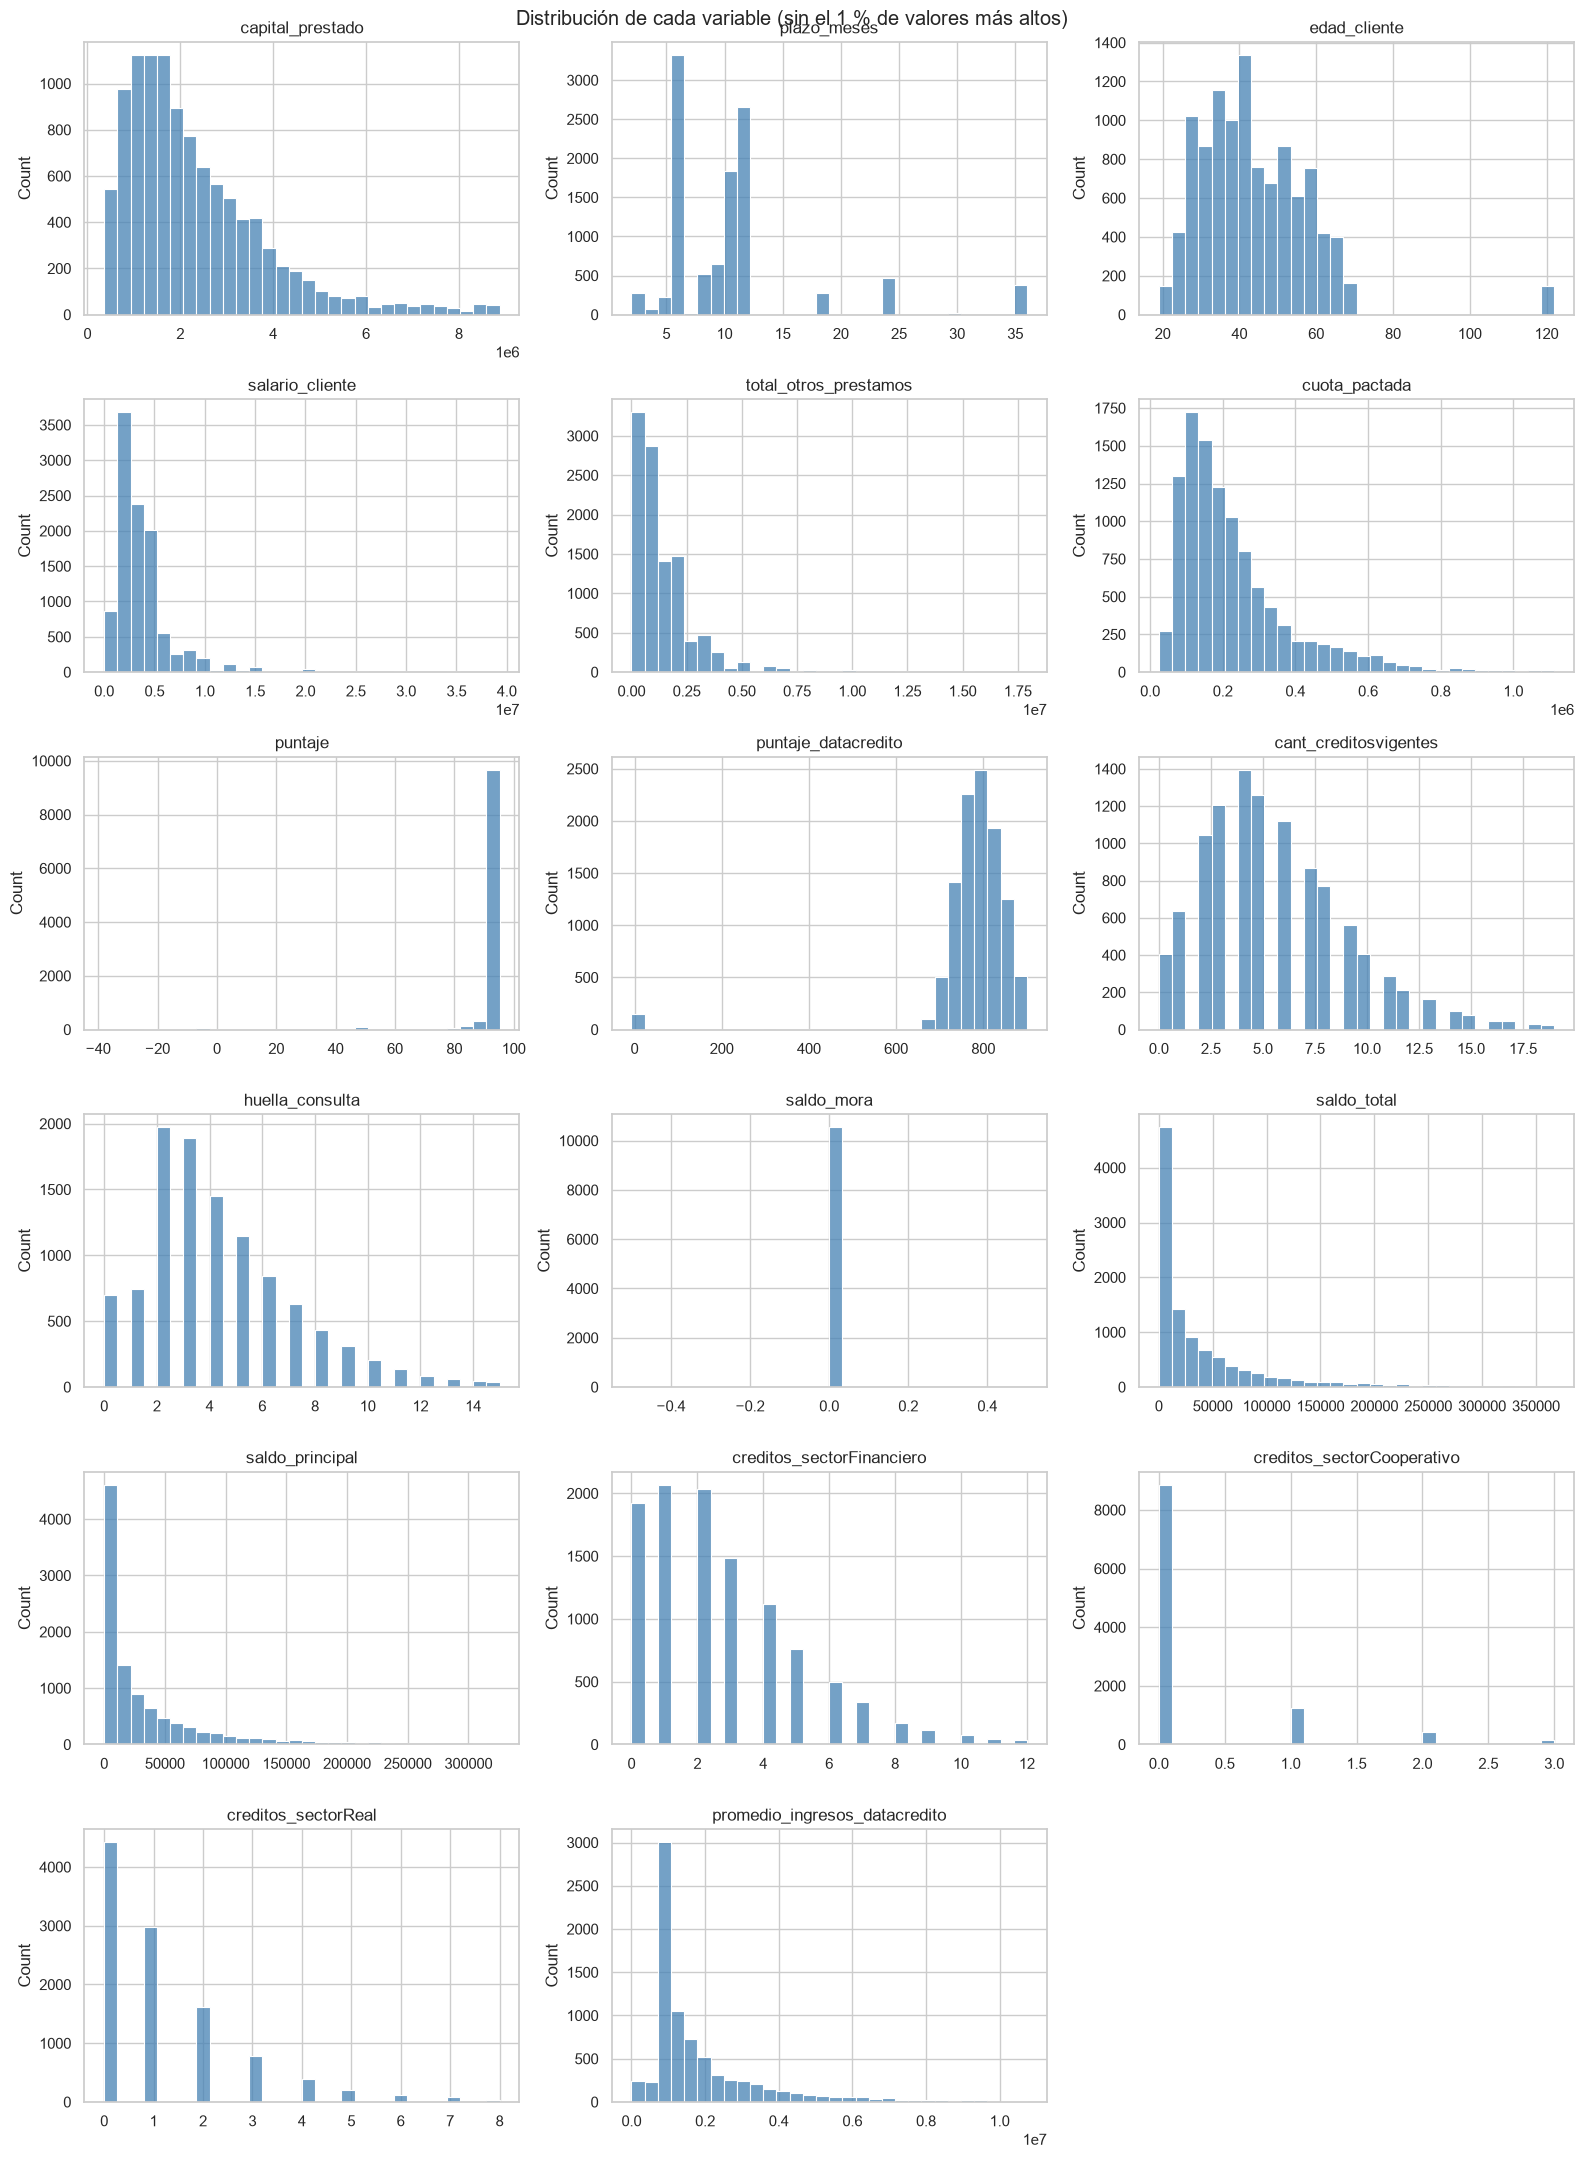

In [12]:
fig, axes = plt.subplots(6, 3, figsize=(16, 22))
axes = axes.flatten()
for i, c in enumerate(columnas_numericas):
    serie = df[c].dropna()
    serie = serie[serie <= serie.quantile(0.99)]
    sns.histplot(serie, bins=30, ax=axes[i], color="steelblue")
    axes[i].set_title(c)
    axes[i].set_xlabel("")
for j in range(len(columnas_numericas), len(axes)):
    axes[j].axis("off")
plt.suptitle("Distribución de cada variable (sin el 1 % de valores más altos)")
plt.tight_layout()
plt.show()

Se quitó el 1 % de valores más altos para que las gráficas se puedan leer; si no, los datos gigantes aplastarían todo. Qué se observa:

- `capital_prestado`, `cuota_pactada`, `salario_cliente`: forma de "rampa" con cola larga a la derecha, típica del dinero.
- `edad_cliente`: hay un grupo suelto cerca de 120 años. Son las 150 edades mayores de 90, que no pueden ser reales.
- `puntaje`: casi todo está en 95. Casi no varía.
- `puntaje_datacredito`: forma de campana alrededor de 800, con un grupo en 0.
- `plazo_meses`: se concentra en 6 y 12 meses, con otros valores en 18, 24 y 36.
- `saldo_mora`: se ve vacía porque más del 99 % es 0.

## 2.5 Valores extremos
Un valor extremo es un dato muy lejos del resto. Se detectan con la regla del IQR: es extremo lo que queda por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR.

In [13]:
def contar_atipicos(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

atipicos = pd.DataFrame({"cantidad": {c: contar_atipicos(df[c].dropna()) for c in columnas_numericas}})
atipicos["porcentaje"] = (atipicos["cantidad"] / len(df) * 100).round(1)
atipicos.sort_values("porcentaje", ascending=False)

,cantidad,porcentaje
creditos_sectorCooperativo,1895,17.6
puntaje,1356,12.6
saldo_total,970,9.0
saldo_principal,951,8.8
plazo_meses,869,8.1
promedio_ingresos_datacredito,784,7.3
cuota_pactada,765,7.1
salario_cliente,718,6.7
total_otros_prestamos,589,5.5
capital_prestado,550,5.1


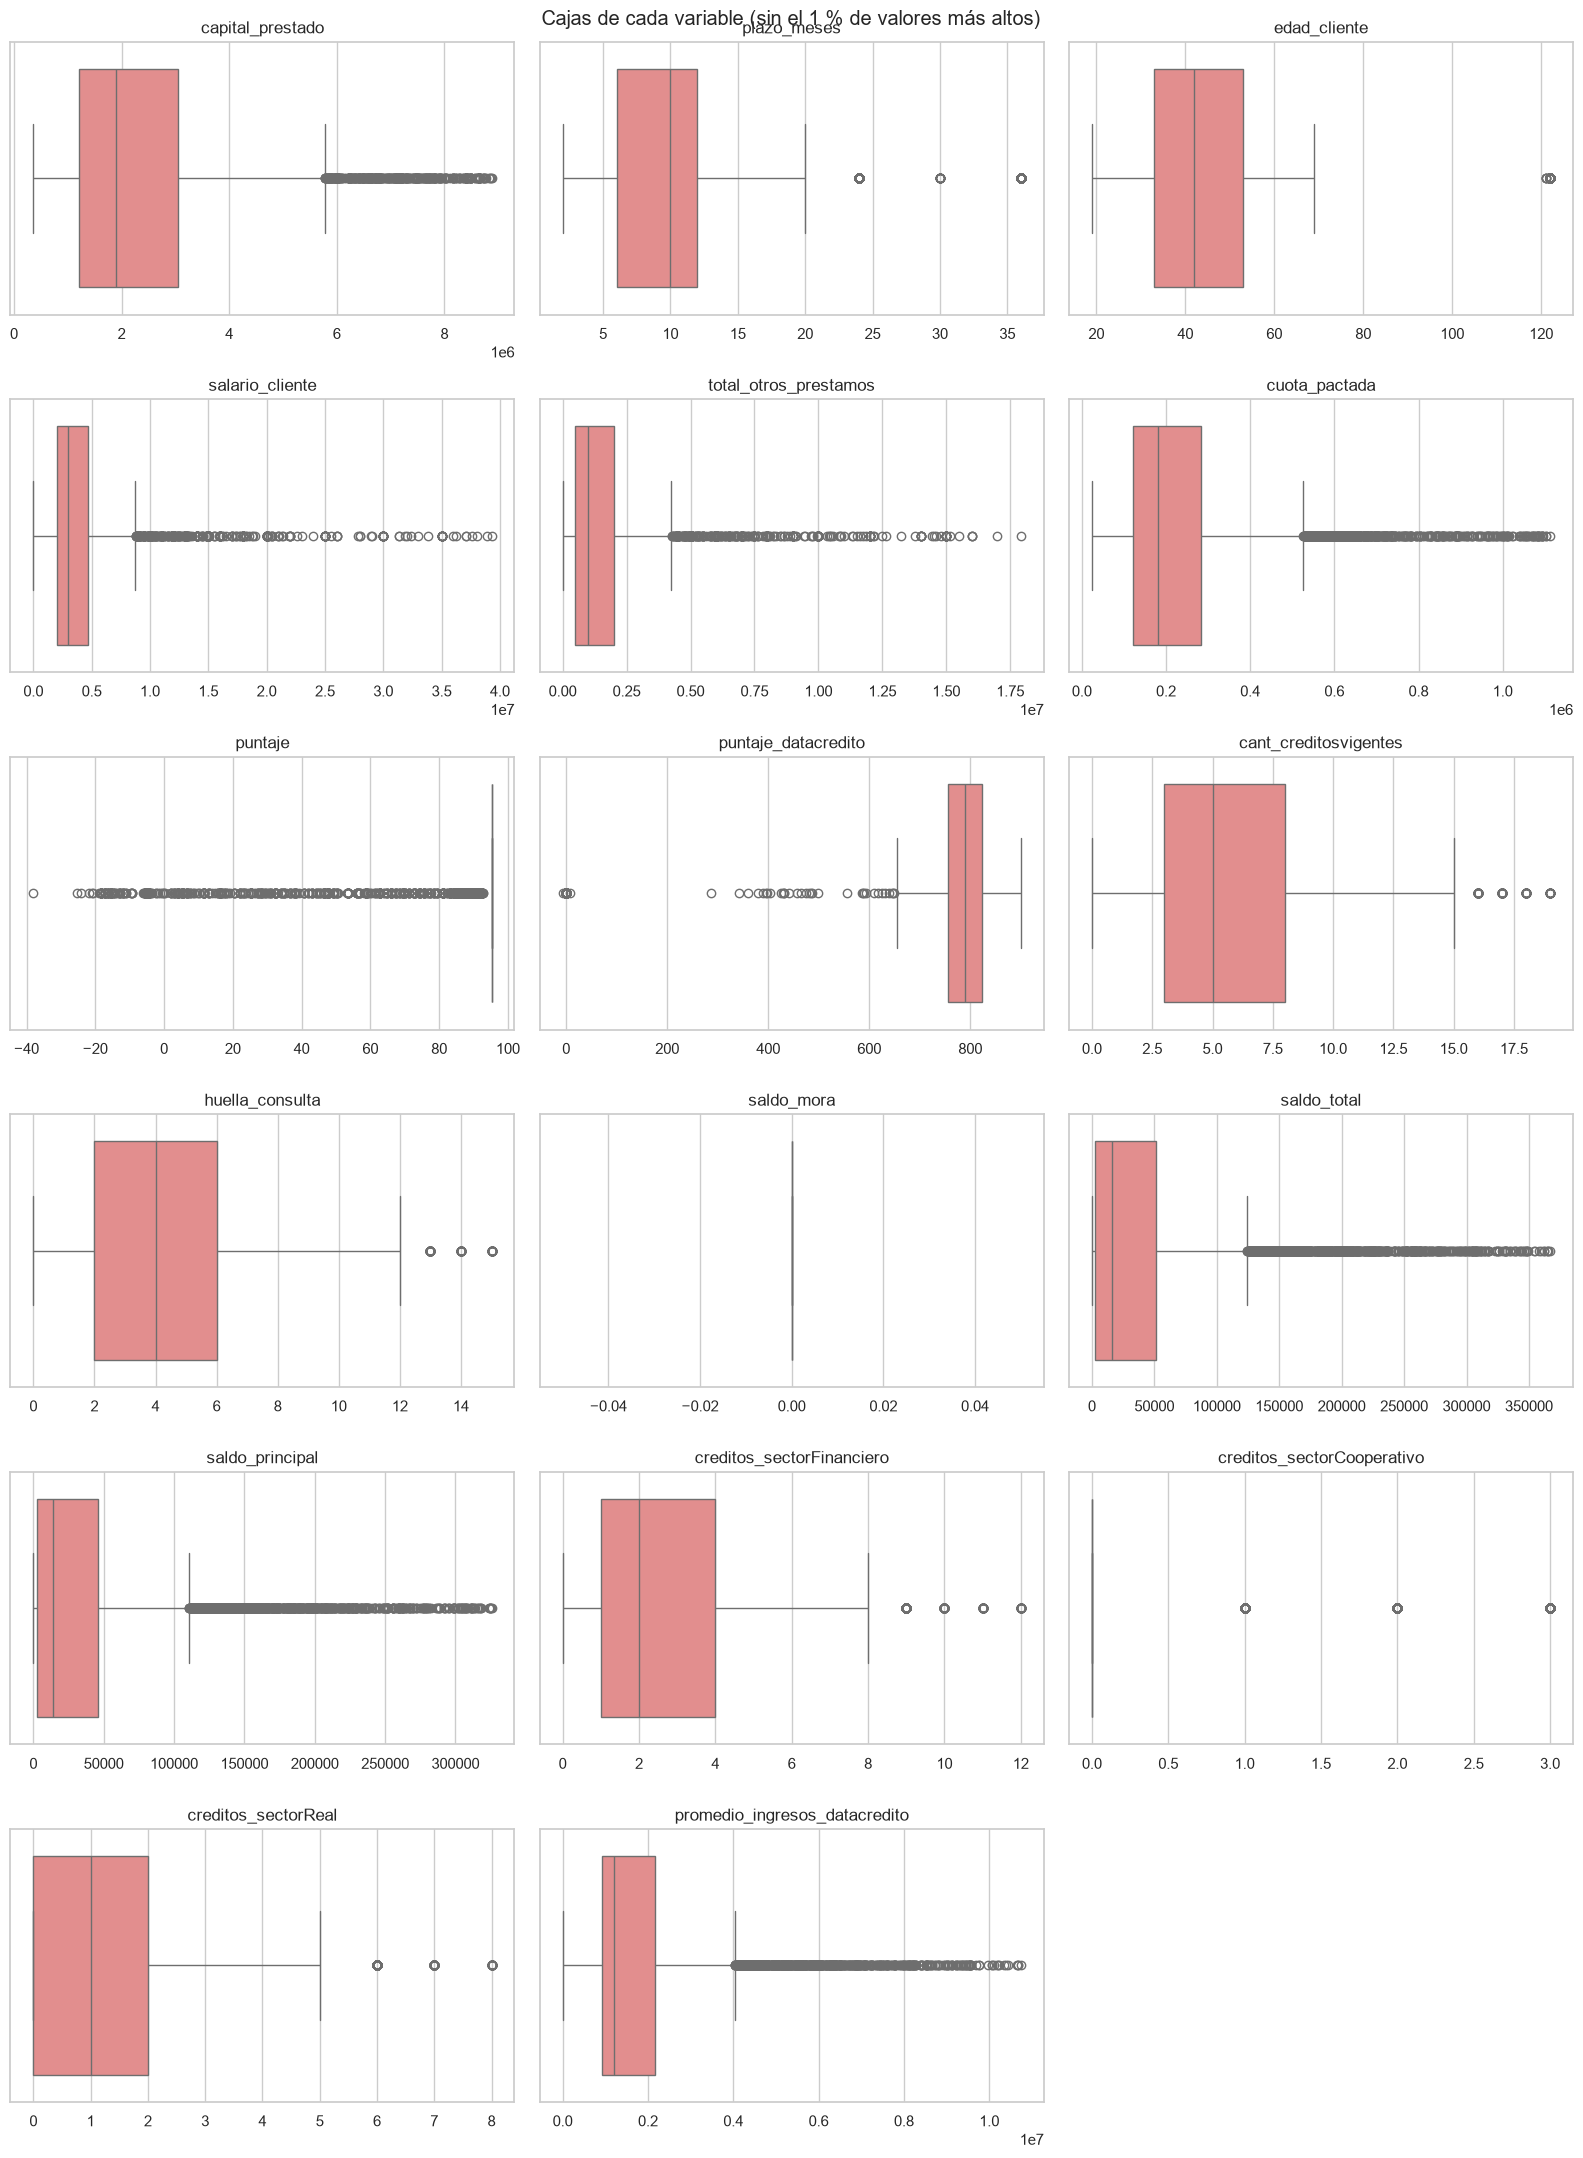

In [14]:
fig, axes = plt.subplots(6, 3, figsize=(16, 22))
axes = axes.flatten()
for i, c in enumerate(columnas_numericas):
    serie = df[c].dropna()
    serie = serie[serie <= serie.quantile(0.99)]
    sns.boxplot(x=serie, ax=axes[i], color="lightcoral")
    axes[i].set_title(c)
    axes[i].set_xlabel("")
for j in range(len(columnas_numericas), len(axes)):
    axes[j].axis("off")
plt.suptitle("Cajas de cada variable (sin el 1 % de valores más altos)")
plt.tight_layout()
plt.show()

**Qué se observa:**
- Casi todas las variables tienen valores extremos por la derecha. Es normal en dinero y conteos.
- `creditos_sectorCooperativo` tiene 17,6 % de extremos solo porque casi todos valen 0, así que cualquier valor distinto de 0 cuenta como extremo.
- `puntaje` tiene 12,6 %: casi todos valen 95,23 y los pocos valores bajos se marcan como extremos.
- `saldo_total`, `saldo_principal` y `plazo_meses` tienen alrededor de 8 a 9 %.
- Un valor extremo no siempre es un error. Los de `salario_cliente` (hasta 22.000 millones) y `edad_cliente` (más de 120) sí parecen errores; los de saldos pueden ser casos reales con deudas altas.

## 2.6 Variables de categorías

In [ ]:
for c in columnas_categoricas:
    print(c)
    tabla = pd.DataFrame({
        "cantidad": df[c].value_counts(dropna=False),
        "porcentaje": (df[c].value_counts(dropna=False, normalize=True) * 100).round(1)
    })
    display(tabla)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, columnas_categoricas):
    sns.countplot(data=df, x=c, ax=ax, color="steelblue")
    ax.set_title(c)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

tipo_credito


,cantidad,porcentaje
tipo_credito,,
4,7747,72.0
9,2876,26.7
10,116,1.1
6,21,0.2
7,2,0.0
68,1,0.0


tipo_laboral


,cantidad,porcentaje
tipo_laboral,,
Empleado,6754,62.8
Independiente,4009,37.2


tendencia_ingresos


,cantidad,porcentaje
tendencia_ingresos,,
Creciente,5294,49.2
NaN,2990,27.8
Decreciente,1291,12.0
Estable,1188,11.0


**Qué se observa:**
- `tipo_credito`: el tipo 4 concentra el 72,0 % y el tipo 9 el 26,7 %. Los tipos 10, 6, 7 y 68 suman menos del 2 %; son tan pocos que habrá que agruparlos como "otros" más adelante.
- `tipo_laboral`: 62,8 % empleados y 37,2 % independientes.
- `tendencia_ingresos`: 49,2 % creciente, 12,0 % decreciente, 11,0 % estable y 27,8 % sin información.

## 2.7 Valores raros: reglas de revisión

In [ ]:
raros = pd.DataFrame({
    "regla": [
        "edad menor de 18",
        "edad mayor de 90",
        "salario igual a 0",
        "salario mayor a 50 millones",
        "puntaje menor que 0",
        "puntaje_datacredito menor o igual a 0",
        "plazo mayor a 48 meses",
        "otros préstamos mayor a 1.000 millones",
        "cuota mayor al salario (con salario > 0)",
    ],
    "cantidad": [
        (df.edad_cliente < 18).sum(),
        (df.edad_cliente > 90).sum(),
        (df.salario_cliente == 0).sum(),
        (df.salario_cliente > 5e7).sum(),
        (df.puntaje < 0).sum(),
        (df.puntaje_datacredito <= 0).sum(),
        (df.plazo_meses > 48).sum(),
        (df.total_otros_prestamos > 1e9).sum(),
        ((df.salario_cliente > 0) & (df.cuota_pactada > df.salario_cliente)).sum(),
    ],
})
raros["porcentaje"] = (raros["cantidad"] / len(df) * 100).round(2)
raros

In [ ]:
print(df[df.edad_cliente > 90]["edad_cliente"].value_counts())
print(df.plazo_meses.value_counts().sort_index())

## 2.8 Conclusiones

- **Edad:** 150 clientes (1,4 %) tienen más de 90 años y casi todos (144) tienen exactamente 122. No es una edad real; parece un valor de relleno. Regla de validación: edad entre 18 y 90.
- **Salario:** 24 salarios valen 0 y 97 superan los 50 millones, con un máximo de 22.000 millones. Hay que revisarlos o limitarlos.
- **Puntaje:** 135 registros tienen puntaje negativo y casi todos los demás valen 95,23. Variable con muy poca variación y sospechosa.
- **puntaje_datacredito:** 146 registros con valor 0 o negativo, que no parecen puntajes reales.
- **Plazo:** casi todo está entre 2 y 36 meses; hay 1 caso de 48 y 1 de 90. Los plazos más comunes son 6 y 12 meses.
- **Tipo de crédito:** 4 y 9 cubren el 98,7 %; los otros 4 tipos son muy raros.
- **Distribuciones:** las variables de dinero tienen forma de rampa con cola larga a la derecha; se podrían transformar con logaritmo en ingeniería de características.

# PARTE 3. COMPARAR CADA VARIABLE CON EL PAGO A TIEMPO

## 3.1 Cuántos pagan y cuántos no

In [ ]:
resumen_objetivo = pd.DataFrame({
    "cantidad": df["Pago_atiempo"].value_counts(),
    "porcentaje": (df["Pago_atiempo"].value_counts(normalize=True) * 100).round(1)
})
resumen_objetivo

**Qué se observa:** 10.252 clientes (95,3 %) pagaron a tiempo y 511 (4,7 %) no. Los datos están **muy desbalanceados**. Un modelo que dijera "todos pagan" acertaría el 95,3 % y no serviría de nada. Por eso, más adelante, se evaluará con recall, F1 y AUC, y no solo con exactitud (accuracy).

## 3.2 Variables numéricas: ¿cambian entre quienes pagan y quienes no?

In [ ]:
comp = df.groupby("Pago_atiempo")[columnas_numericas].median().T
comp.columns = ["mediana_no_pago", "mediana_pago"]
comp["media_no_pago"] = df[df.Pago_atiempo == 0][columnas_numericas].mean()
comp["media_pago"] = df[df.Pago_atiempo == 1][columnas_numericas].mean()
with pd.option_context("display.float_format", "{:,.2f}".format, "display.width", 200):
    display(comp)

Se comparan la mediana y la media de cada variable entre los que **no pagaron** (0) y los que **sí pagaron** (1). La mediana es más confiable aquí porque casi todas las variables tienen valores extremos.

In [ ]:
fig, axes = plt.subplots(6, 3, figsize=(16, 24))
axes = axes.flatten()
for i, c in enumerate(columnas_numericas):
    d = df[[c, "Pago_atiempo"]].dropna()
    d = d[d[c] <= d[c].quantile(0.99)]
    sns.boxplot(data=d, x="Pago_atiempo", y=c, hue="Pago_atiempo",
                palette=["tomato", "steelblue"], legend=False, ax=axes[i])
    axes[i].set_title(c)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
for j in range(len(columnas_numericas), len(axes)):
    axes[j].axis("off")
plt.suptitle("Cada variable según si pagó (1) o no pagó (0) a tiempo")
plt.tight_layout()
plt.show()

## 3.3 Qué tan relacionada está cada variable con el pago

In [ ]:
cor = (df[columnas_numericas + ["Pago_atiempo"]].corr()["Pago_atiempo"]
       .drop("Pago_atiempo").sort_values(key=abs, ascending=False).round(3))
display(cor)

plt.figure(figsize=(8, 6))
sns.barplot(x=cor.values, y=cor.index, color="steelblue")
plt.title("Correlación de cada variable con Pago_atiempo")
plt.xlabel("Correlación (de -1 a 1)")
plt.show()

**Cómo leerlo:** la correlación va de -1 a 1. Cerca de 0 significa que casi no hay relación. Positiva significa que, si la variable sube, es más probable pagar. Negativa significa lo contrario.

**Qué se observa:**
- `puntaje` tiene una correlación de **0,92**, muy por encima de todas las demás. Esto es una señal de alerta que se revisa en 3.6.
- Las otras variables tienen relaciones muy débiles (menos de 0,08 en valor absoluto). Las más altas son `huella_consulta` (-0,074), `saldo_mora` (-0,073), `puntaje_datacredito` (0,068) y `plazo_meses` (-0,063).
- Una correlación baja no significa que la variable no sirva: solo mide relaciones en línea recta.

## 3.4 Variables de categorías: ¿en cuál se paga más?

In [ ]:
# Agrupamos lo que es muy poco frecuente y marcamos los vacíos
df["tipo_credito_grupo"] = df["tipo_credito"].astype(str).where(
    df["tipo_credito"].astype(str).isin(["4", "9"]), "Otros")
df["tendencia_ingresos_2"] = df["tendencia_ingresos"].astype(object).fillna("Sin información")

def tasa(data, col):
    return data.groupby(col, observed=True)["Pago_atiempo"].agg(
        clientes="count",
        no_pagan=lambda s: int((s == 0).sum()),
        pct_pago=lambda s: round(s.mean() * 100, 1))

for c in ["tipo_credito_grupo", "tipo_laboral", "tendencia_ingresos_2"]:
    display(tasa(df, c))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ["tipo_credito_grupo", "tipo_laboral", "tendencia_ingresos_2"]):
    t = (df.groupby(c)["Pago_atiempo"].mean() * 100).reset_index()
    sns.barplot(data=t, x=c, y="Pago_atiempo", ax=ax, color="steelblue")
    ax.set_ylim(80, 100)
    ax.axhline(df["Pago_atiempo"].mean() * 100, color="red", linestyle="--")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom")
    ax.set_title(c)
    ax.set_xlabel("")
    ax.set_ylabel("% que paga a tiempo")
plt.tight_layout()
plt.show()

La línea roja es el promedio general (95,3 %). El eje empieza en 80 % para ver mejor las diferencias.

**Qué se observa:**
- **Tipo de crédito:** los tipos 4 y 9 pagan igual (95,3 %). El grupo "Otros" (tipos 6, 7, 10 y 68) baja a 91,4 %, pero son solo 140 clientes.
- **Tipo laboral:** los empleados pagan un poco más (95,7 %) que los independientes (94,5 %). La diferencia es pequeña.
- **Tendencia de ingresos:** Creciente 96,1 %, Estable 95,4 %, Sin información 94,4 % y Decreciente 93,7 %. Tiene sentido: quien ve bajar sus ingresos paga un poco peor.
- En general, las categorías separan poco. Ninguna variable de categoría decide el pago por sí sola.

## 3.5 Mora y puntaje de DataCrédito

In [ ]:
df["grupo_mora"] = np.where(df["saldo_mora"].isna(), "Sin dato",
                    np.where(df["saldo_mora"] > 0, "Con mora", "Sin mora"))

df["rango_dc"] = pd.cut(df["puntaje_datacredito"], [-10, 0, 600, 700, 800, 900, 1000],
                        labels=["0 o menos", "1-600", "601-700", "701-800", "801-900", "901-1000"])

display(tasa(df, "grupo_mora"))
display(tasa(df, "rango_dc"))

**Qué se observa:**
- **Saldo en mora:** solo 55 clientes tienen mora y de ellos paga el 63,6 %, contra 95,5 % de los que no tienen mora. Son pocos clientes, pero es una señal muy fuerte. Por eso `saldo_mora` **no se elimina**.
- **Puntaje de DataCrédito:** a mayor puntaje, mayor pago (de 38,5 % en el rango 1-600 a 97,1 % en 901-1000). Es una relación lógica y útil.
- Los 146 clientes con puntaje 0 o menos pagan 93,2 %, casi como el promedio. Ese 0 parece "sin dato", no un puntaje malo.

## 3.6 Revisión del puntaje interno: posible fuga de datos

In [ ]:
df["rango_puntaje"] = pd.cut(df["puntaje"], [-100, 0, 50, 90, 95.2, 200],
                             labels=["menor a 0", "0 a 50", "50 a 90", "90 a 95,2", "95,23 o más"])
display(tasa(df, "rango_puntaje"))

**Qué se observa:** el `puntaje` separa casi perfecto a los que pagan de los que no:
- Con puntaje menor a 50 (426 clientes), **nadie** pagó a tiempo (0 %).
- Con puntaje de 90 o más (9.719 clientes), **todos** pagaron (100 %).
- Solo en el rango 50 a 90 hay mezcla (86,2 % de pago).

**Por qué es un problema:** un puntaje que predice tan perfecto probablemente se calculó *después* de saber si el cliente pagó. Eso se llama **fuga de datos** (*data leakage*). Un modelo con esta variable daría resultados excelentes en las pruebas, pero no serviría para decidir un crédito nuevo, porque ese puntaje no existe antes de prestar.

**Decisión provisional:** se va a entrenar el modelo **sin** `puntaje`, o se probarán las dos versiones para comparar. Se debe confirmar con el docente cuándo se calcula esta variable.

## 3.7 Pago a lo largo del tiempo y según el plazo

In [ ]:
df["mes"] = df["fecha_prestamo"].dt.to_period("M").astype(str)
por_mes = df.groupby("mes")["Pago_atiempo"].agg(clientes="count", pct_pago=lambda s: round(s.mean() * 100, 1))
display(por_mes.T)

por_plazo = df.groupby("plazo_meses")["Pago_atiempo"].agg(clientes="count", pct_pago=lambda s: round(s.mean() * 100, 1))
display(por_plazo.T)

**Qué se observa:** el porcentaje de pago por mes se mueve entre 90,9 % y 98,3 %. No hay una tendencia clara. Los meses con pocos préstamos (por ejemplo, abril de 2026 con 11) varían mucho solo por azar. Por plazo, los créditos de 36 meses pagan algo menos (86,8 %) que los cortos (94 % a 96 %).

## 3.8 Conclusiones

- **Desbalance:** 95,3 % pagan y 4,7 % no. Se evaluará con recall, F1 y AUC.
- **Puntaje interno (`puntaje`):** relación casi perfecta con el pago (correlación 0,92). Hay sospecha de fuga de datos y no debe usarse sin confirmar.
- **Mora:** los 55 clientes con mora pagan solo 63,6 %, contra 95,5 % del resto. Es una señal fuerte aunque rara.
- **Puntaje DataCrédito:** a mayor puntaje, mayor pago. Variable útil.
- **Tendencia de ingresos y tipo laboral:** diferencias pequeñas pero con lógica (creciente y empleado pagan algo mejor).
- **Tipo de crédito:** el grupo "Otros" paga menos (91,4 %), pero son pocos clientes.
- **Resto de variables numéricas:** relación débil con el pago (correlación menor a 0,08). Probablemente aporten más combinadas que solas.

# PARTE 4. COMPARAR VARIAS VARIABLES A LA VEZ

## 4.1 Mapa de relaciones entre variables

In [ ]:
corr = df[columnas_numericas + ["Pago_atiempo"]].corr(method="spearman")

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".1f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Relación entre variables (correlación de Spearman)")
plt.show()

Se usa la correlación de **Spearman** porque casi todas las variables tienen valores extremos y no forman una línea recta; Spearman se ve menos afectada por esos extremos. Rojo = suben juntas. Azul = una sube y la otra baja. Blanco = sin relación.

## 4.2 Variables que dicen casi lo mismo

In [ ]:
pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().reset_index()
pares.columns = ["variable_1", "variable_2", "correlacion"]
fuertes = pares[pares["correlacion"].abs() >= 0.7].sort_values("correlacion", key=abs, ascending=False).round(2)
fuertes

**Qué se observa:** hay 4 pares con relación fuerte (0,7 o más):
- `saldo_total` y `saldo_principal` (0,95): casi son la misma información. En el modelo se puede dejar solo una.
- `cant_creditosvigentes` y `creditos_sectorFinanciero` (0,76): lógico, porque la mayoría de los créditos vigentes son del sector financiero.
- `capital_prestado` y `cuota_pactada` (0,75): a más capital, más cuota.
- `salario_cliente` y `total_otros_prestamos` (0,71): quien gana más debe más.

Si dos variables dicen lo mismo, no aportan el doble. Más adelante se decidirá si se quita una de cada par.

## 4.3 Variables nuevas: cuánto pesa el crédito frente al salario

In [ ]:
# Si el salario es 0 no se puede dividir: queda vacío
salario = df["salario_cliente"].where(df["salario_cliente"] > 0)

df["cuota_sobre_salario"] = df["cuota_pactada"] / salario
df["capital_sobre_salario"] = df["capital_prestado"] / salario
df["otros_prestamos_sobre_salario"] = df["total_otros_prestamos"] / salario

nuevas = ["cuota_sobre_salario", "capital_sobre_salario", "otros_prestamos_sobre_salario"]
display(df.groupby("Pago_atiempo")[nuevas].median().round(3))

for c in nuevas:
    d = df[[c, "Pago_atiempo"]].dropna().copy()
    d["grupo"] = pd.qcut(d[c], 5, duplicates="drop")
    print(c)
    display(d.groupby("grupo", observed=True)["Pago_atiempo"].agg(
        clientes="count", pct_pago=lambda s: round(s.mean() * 100, 1)))

Se crearon 3 variables que comparan lo que debe el cliente con lo que gana. Se dividió cada una en 5 grupos del mismo tamaño (de menor a mayor) para ver si cambia el pago.

**Qué se observa:**
- La mediana de `cuota_sobre_salario` es casi igual en quienes pagan (0,061) y en quienes no (0,061). Esta variable casi no separa.
- `capital_sobre_salario`: el grupo más alto (se pide más de 1,1 veces el salario) paga un poco menos (93,9 %) que el resto (95 % a 96 %).
- `otros_prestamos_sobre_salario`: el grupo más bajo paga un poco menos (93,2 %). Es una diferencia pequeña y no muy lógica.
- Conclusión honesta: estas variables nuevas aportan **poca señal por sí solas**. Se dejan para probar en el modelo, pero no se espera que sean las más importantes.

## 4.4 Cruces entre dos variables de categorías

In [ ]:
tab1 = (df.pivot_table(index="tipo_laboral", columns="tendencia_ingresos_2",
                       values="Pago_atiempo", aggfunc="mean", observed=True) * 100).round(1)
tab2 = (df.pivot_table(index="tipo_credito_grupo", columns="tipo_laboral",
                       values="Pago_atiempo", aggfunc="mean", observed=True) * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(tab1, annot=True, fmt=".1f", cmap="RdYlGn", ax=axes[0])
axes[0].set_title("% que paga: tipo laboral y tendencia de ingresos")
sns.heatmap(tab2, annot=True, fmt=".1f", cmap="RdYlGn", ax=axes[1])
axes[1].set_title("% que paga: tipo de crédito y tipo laboral")
plt.tight_layout()
plt.show()

**Qué se observa:**
- El independiente con ingresos decrecientes es el grupo que menos paga (92,7 %). El empleado con ingresos crecientes es el que más paga (96,4 %). Se suman los dos efectos vistos en la Parte 3.
- En el tipo de crédito "Otros", los empleados pagan solo 88,8 %, mientras que los independientes pagan 97,6 %. Es el único cruce que se invierte, pero son pocos clientes (140 en total), así que no es confiable.

## 4.5 Dos variables a la vez en una gráfica

In [ ]:
muestra = df[["puntaje_datacredito", "cuota_sobre_salario", "Pago_atiempo"]].dropna()
muestra = muestra[(muestra["puntaje_datacredito"] > 0) &
                  (muestra["cuota_sobre_salario"] < muestra["cuota_sobre_salario"].quantile(0.99))]

plt.figure(figsize=(9, 6))
pagan = muestra[muestra["Pago_atiempo"] == 1].sample(1500, random_state=1)
no_pagan = muestra[muestra["Pago_atiempo"] == 0]
sns.scatterplot(data=pagan, x="puntaje_datacredito", y="cuota_sobre_salario",
                color="steelblue", alpha=0.3, label="Pagó (muestra de 1.500)")
sns.scatterplot(data=no_pagan, x="puntaje_datacredito", y="cuota_sobre_salario",
                color="tomato", alpha=0.7, label="No pagó")
plt.title("Puntaje de DataCrédito y peso de la cuota, según si pagó")
plt.show()

Se dibuja una muestra de 1.500 clientes que pagan (para que la gráfica no se llene) y todos los que no pagan.

**Qué se observa:** los puntos rojos (no pagó) están mezclados con los azules en casi toda la gráfica. Solo hay un poco más de rojo en los puntajes bajos. No se ve una frontera clara, lo que confirma que **separar a los que no pagan es difícil** con estas variables y que se necesitará un modelo que combine varias.

## 4.6 Conclusiones

- **Variables repetidas:** `saldo_total` y `saldo_principal` (0,95) casi son la misma. También hay relación fuerte entre capital y cuota, y entre salario y otros préstamos.
- **Variables nuevas (cuota, capital y otros préstamos sobre salario):** señal débil, pero se conservan para probarlas en el modelo.
- **Cruces:** independiente con ingresos decrecientes es el grupo que menos paga (92,7 %).
- **Dificultad del problema:** quienes no pagan están mezclados con quienes sí pagan, así que ninguna variable sola alcanza para separarlos.

# PARTE 5. REGLAS DE LIMPIEZA Y CONCLUSIONES FINALES

## 5.1 Reglas de validación: qué se hace con cada valor raro

| Variable | Regla | Qué se hace | Por qué |
|---|---|---|---|
| edad_cliente | Debe estar entre 18 y 90 | Valores fuera pasan a vacío (150) | El 122 es un valor de relleno, no una edad real |
| salario_cliente | Debe ser mayor que 0 y no pasar de 50 millones | Valores fuera pasan a vacío (121) | Hay salarios de 0 y de hasta 22.000 millones, que son errores |
| puntaje_datacredito | Debe ser mayor que 0 | Valores de 0 o menos pasan a vacío (146) | El 0 significa "sin puntaje", no un puntaje malo |
| plazo_meses | No más de 48 meses | El valor de 90 pasa a vacío (1) | Es un caso aislado, muy lejos del resto |
| total_otros_prestamos | No más de 1.000 millones | Valores fuera pasan a vacío (13) | Son montos imposibles para el tipo de cliente |
| tipo_credito | Solo 4, 9 y "Otros" | Se agrupan los tipos 6, 7, 10 y 68 | Cada uno tiene muy pocos clientes |
| tendencia_ingresos | Los vacíos son una categoría | Se llena con "Sin información" | Es más de un cuarto de los datos y paga distinto (94,4 %) |

Los valores raros **no se borran**: se dejan vacíos para rellenarlos después, en la etapa de ingeniería de características. Así no se pierden clientes ni se pierde información de las demás columnas.

## 5.2 Aplicar las reglas en una copia

In [ ]:
# Se trabaja en una COPIA: el df original no se toca
df_limpio = df.copy()

reglas = {
    "edad_cliente": (df_limpio["edad_cliente"] < 18) | (df_limpio["edad_cliente"] > 90),
    "salario_cliente": (df_limpio["salario_cliente"] <= 0) | (df_limpio["salario_cliente"] > 5e7),
    "puntaje_datacredito": df_limpio["puntaje_datacredito"] <= 0,
    "plazo_meses": df_limpio["plazo_meses"] > 48,
    "total_otros_prestamos": df_limpio["total_otros_prestamos"] > 1e9,
}

resultado = []
for columna, condicion in reglas.items():
    resultado.append({"variable": columna, "valores_pasados_a_vacio": int(condicion.sum())})
    df_limpio.loc[condicion, columna] = np.nan

df_limpio["tipo_credito"] = df_limpio["tipo_credito"].astype(str).where(
    df_limpio["tipo_credito"].astype(str).isin(["4", "9"]), "Otros")
df_limpio["tendencia_ingresos"] = df_limpio["tendencia_ingresos"].astype(object).fillna("Sin información")

display(pd.DataFrame(resultado))

nulos = df_limpio.isna().sum()
print("Vacíos que quedan después de aplicar las reglas:")
display(nulos[nulos > 0])

**Qué se observa:** las reglas dejaron vacíos 150 valores de edad, 121 de salario, 146 de puntaje_datacredito, 13 de otros préstamos y 1 de plazo. Ahora `edad_cliente` va de 19 a 69 años y `plazo_meses` llega a 48 como máximo. Todavía queda por revisar que algunos salarios son muy bajos (mínimo 1.000 pesos), lo cual también es sospechoso.

Los vacíos que quedan se rellenarán en `ft_engineering.py`.

## 5.3 Transformaciones que se aplicarán en el modelo

| Qué | Para qué variables | Por qué |
|---|---|---|
| Rellenar vacíos con la mediana | Variables numéricas con vacíos | La mediana no se afecta por valores extremos |
| Logaritmo | Dinero: capital, cuota, salario, saldos, otros préstamos | Tienen cola larga a la derecha; el logaritmo la aplana |
| Convertir categorías en columnas 0/1 | tipo_credito, tipo_laboral, tendencia_ingresos | Los modelos necesitan números |
| Llevar a la misma escala | Variables numéricas | Para que las de números grandes no dominen a las pequeñas |
| Quitar una de cada par repetido | saldo_total o saldo_principal | Dicen casi lo mismo (0,95) |
| Crear variables nuevas | cuota, capital y otros préstamos sobre salario; mes del préstamo | Comparan el crédito con la capacidad del cliente |
| Marcar clientes con mora | saldo_mora mayor que 0 | Son pocos, pero pagan mucho menos (63,6 %) |
| Quitar `puntaje` (o probar con y sin) | puntaje | Posible fuga de datos |
| Balancear las clases | Solo en entrenamiento | Solo 4,7 % no paga; se puede usar class_weight o SMOTE |

## 5.4 Conclusiones generales del EDA

**Los datos**
- 10.763 créditos y 23 variables. Se eliminó `saldo_mora_codeudor` (casi todo 0). No hay filas repetidas.
- Había errores de carga: 58 valores numéricos en `tendencia_ingresos`, edades de 122 años, salarios de 0 y de hasta 22.000 millones.
- Los nulos más grandes están en `tendencia_ingresos` (27,8 %) y `promedio_ingresos_datacredito` (27,2 %).

**El problema**
- Solo el 4,7 % de los clientes no paga a tiempo: los datos están muy desbalanceados. Se evaluará con recall, F1 y AUC, no solo con accuracy.

**Qué variables dicen más sobre el pago**
- `puntaje` separa casi perfecto a quien paga de quien no (correlación 0,92). Parece fuga de datos y se debe confirmar con el docente.
- `saldo_mora`: el 63,6 % de quienes tienen mora paga, contra 95,5 % de quienes no la tienen.
- `puntaje_datacredito`: a mayor puntaje, mayor pago.
- `tendencia_ingresos` y `tipo_laboral`: diferencias pequeñas pero lógicas.
- El resto de variables tiene relación débil con el pago cuando se miran solas.